# Késni fog-e a járat? — 1. rész: adat-előkészítés és EDA

**Adat:** 2015 Flight Delays and Cancellations (Kaggle `usdot/flight-delays`), a **Delta** (`DL`) járatai. A projekt terve: `projektterv.md`.

**Szabály:** az EDA csak a **tanító időszakon** (január–szeptember) készül; az október a rés, a november–december a zárolt teszt, ide nem nézünk.
Az EDA-ban a késés okait és a tényleges időpontokat is használhatjuk *leírásra*, de ezek a modellben szivárgás lennének (lásd a terv 3. pontját).

**Futtatás:** a Kaggle-ről letöltött `flights.csv`, `airports.csv` és `airlines.csv` a `data/` mappában legyen. Az első futás kivágja a Delta-járatokat
és elmenti őket (`data/delta_2015.pkl`); utána a notebook ebből a gyorsítótárból indul.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 180)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "magenta": "#e87ba4",
     "grey": "#a9a8a2", "ink": "#0b0b0b", "ink2": "#52514e"}
SEQ = LinearSegmentedColormap.from_list("késés", ["#fde3d6", "#eb6834", "#7a2a0c"])     # világos = kevés késés, sötét = sok
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False})
pct = PercentFormatter(1.0, decimals=0)

DATA = Path(os.environ.get("FP_DATA", "data"))
CACHE, TRAFFIC = DATA / "delta_2015.pkl", DATA / "traffic_2015.pkl"

## 1. Betöltés és a Delta-járatok kivágása

Az 5,8 millió soros fájlt **darabonként** olvassuk, csak a szükséges oszlopokkal. Közben két dolgot gyűjtünk:
a Delta-járatokat, és **minden** légitársaság óránkénti indulásainak számát repülőterenként (ez a zsúfoltság-jellemzőhöz kell).

In [2]:
COLS = ["MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "FLIGHT_NUMBER", "TAIL_NUMBER", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
        "SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "DEPARTURE_DELAY", "SCHEDULED_TIME", "DISTANCE", "SCHEDULED_ARRIVAL",
        "ARRIVAL_TIME", "ARRIVAL_DELAY", "DIVERTED", "CANCELLED", "CANCELLATION_REASON",
        "AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]
TXT = {c: str for c in ["AIRLINE", "TAIL_NUMBER", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "CANCELLATION_REASON"]}

if CACHE.exists():
    dl, traffic = pd.read_pickle(CACHE), pd.read_pickle(TRAFFIC)
    n_all = int(traffic.sum())
else:
    parts, traf, n_all = [], [], 0
    for ch in pd.read_csv(DATA / "flights.csv", usecols=COLS, dtype=TXT, chunksize=500_000):
        n_all += len(ch)
        ch["dep_hour"] = (ch.SCHEDULED_DEPARTURE // 100).clip(upper=23)
        traf.append(ch.groupby(["ORIGIN_AIRPORT", "MONTH", "DAY", "dep_hour"]).size())
        parts.append(ch[ch.AIRLINE == "DL"])
    dl = pd.concat(parts, ignore_index=True)
    traffic = pd.concat(traf).groupby(level=[0, 1, 2, 3]).sum().rename("traffic")
    dl.to_pickle(CACHE); traffic.to_pickle(TRAFFIC)

print(f"összes járat: {n_all:,} | Delta: {len(dl):,} ({len(dl) / n_all:.1%}) | gépek: {dl.TAIL_NUMBER.nunique():,} | "
      f"repülőterek: {pd.concat([dl.ORIGIN_AIRPORT, dl.DESTINATION_AIRPORT]).nunique():,}")

összes járat: 5,819,079 | Delta: 875,881 (15.1%) | gépek: 828 | repülőterek: 299


## 2. Alap-előkészítés

Dátum és tervezett indulás (helyi idő; a `2400` éjfélt jelöl), a célváltozó (érkezési késés > 15 perc), és a split-időszakok.

In [3]:
hhmm = dl.SCHEDULED_DEPARTURE.astype(int).clip(upper=2359)
dl["date"] = pd.to_datetime(dict(year=2015, month=dl.MONTH, day=dl.DAY))
dl["sched_dep"] = dl.date + pd.to_timedelta(hhmm // 100, unit="h") + pd.to_timedelta(hhmm % 100, unit="m")
dl["dep_hour"] = (hhmm // 100).astype(int)
dl["delayed"] = (dl.ARRIVAL_DELAY > 15).astype(float).where(dl.ARRIVAL_DELAY.notna())     # törölt / elterelt: NaN
dl["period"] = np.select([dl.MONTH <= 9, dl.MONTH == 10], ["tanító", "rés"], "teszt")
print(dl.period.value_counts().reindex(["tanító", "rés", "teszt"]).to_string())

tr = dl[dl.period == "tanító"].copy()          # MINDEN alábbi EDA csak ezen fut
done = tr[tr.ARRIVAL_DELAY.notna()]             # ténylegesen megérkezett járatok

period
tanító    657462
rés        75552
teszt     142867


## 3. Adatminőség

**Kérdés:** mi hiányzik vagy furcsa? **Döntés:** tisztítási szabályok (a modell előtt, a teszten mechanikusan ugyanúgy).

In [4]:
numeric_code = dl.ORIGIN_AIRPORT.str.fullmatch(r"\d+")
quality = pd.DataFrame({
    "számkódú repülőtér (havonta)": numeric_code.groupby(dl.MONTH).mean(),
    "hiányzó lajstromjel": dl.TAIL_NUMBER.isna().groupby(dl.MONTH).mean(),
    "törölt": dl.CANCELLED.groupby(dl.MONTH).mean(),
    "elterelt": dl.DIVERTED.groupby(dl.MONTH).mean(),
})
print(f"tervezett indulás 2400 (éjfél): {(dl.SCHEDULED_DEPARTURE == 2400).sum()} sor")
quality.style.format("{:.2%}")

tervezett indulás 2400 (éjfél): 0 sor


,számkódú repülőtér (havonta),hiányzó lajstromjel,törölt,elterelt
MONTH,,,,
1,0.00%,0.04%,1.05%,0.10%
2,0.00%,0.00%,2.79%,0.19%
3,0.00%,0.00%,0.71%,0.18%
4,0.00%,0.00%,0.20%,0.18%
5,0.00%,0.00%,0.19%,0.27%
6,0.00%,0.00%,0.31%,0.33%
7,0.00%,0.00%,0.13%,0.31%
8,0.00%,0.00%,0.09%,0.25%
9,0.00%,0.00%,0.01%,0.15%


*Értelmezés:* az adat meglepően tiszta. A „2400” éjfél-érték a Delta tervezett indulásainál egyszer sem fordul elő (0 sor), és a lajstromjel csak 26 járatnál hiányzik (januárban 0,04%). A számkódú repülőterek valóban **csak októberben** fordulnak elő, ott viszont a Delta-járatok 100%-ánál: ez megerősíti, hogy az október a résbe kerüljön. A törlés februárban a legmagasabb (2,79%), az elterelés minden hónapban 0,1–0,33%. **Döntés:** a hiányzó lajstromjelű sorok csak a gép-sorozatos jellemzőkből esnek ki, az októbert nem javítjuk, hanem kihagyjuk, a törölt és elterelt járatok pedig kimaradnak a célból.

## 4. A célváltozó

**Kérdés:** hogyan oszlik el az érkezési késés, és hány járat késik 15 percnél többet? **Döntés:** a cél definíciója és a fő mutató (osztályarány → PR-AUC).

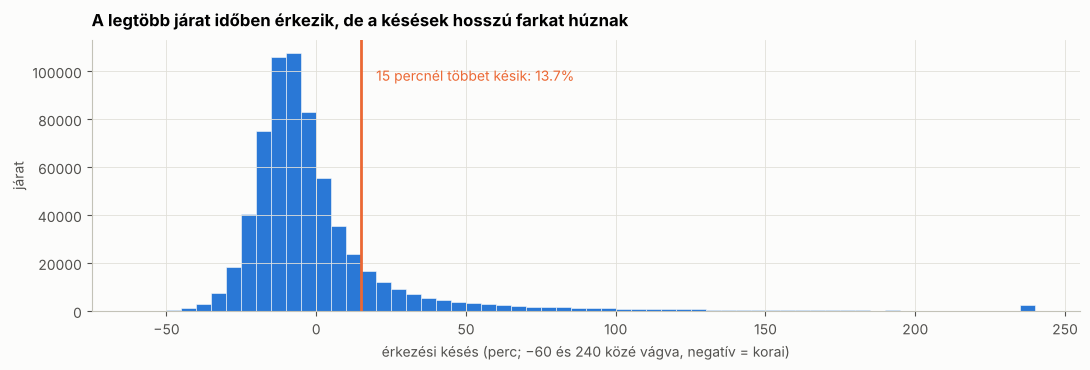

késési arány (> 15 perc): 13.7% | medián -7 perc | 90%: 24 | 95%: 52 | 99%: 156 perc


In [5]:
rate = done.delayed.mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.hist(done.ARRIVAL_DELAY.clip(-60, 240), bins=np.arange(-60, 245, 5), color=C["blue"], edgecolor="#fcfcfb", linewidth=0.4)
ax.axvline(15, color=C["orange"], lw=2)
ax.text(20, ax.get_ylim()[1] * 0.85, f"15 percnél többet késik: {rate:.1%}", color=C["orange"])
ax.set(title="A legtöbb járat időben érkezik, de a késések hosszú farkat húznak",
       xlabel="érkezési késés (perc; −60 és 240 közé vágva, negatív = korai)", ylabel="járat")
plt.tight_layout(); plt.show()
q = done.ARRIVAL_DELAY.quantile([0.5, 0.9, 0.95, 0.99])
print(f"késési arány (> 15 perc): {rate:.1%} | medián {q[0.5]:.0f} perc | 90%: {q[0.9]:.0f} | 95%: {q[0.95]:.0f} | 99%: {q[0.99]:.0f} perc")

*Értelmezés:* a megérkezett tanító járatoknál a medián késés −7 perc, tehát a tipikus Delta-járat korábban ér be. A 15 percnél nagyobb késés aránya **13,7%** (652 391 járatból 89 550). Az eloszlás farka hosszú: a 95. percentilis 52 perc, a 99. percentilis 156 perc. **Döntés:** a cél a bináris `ARRIVAL_DELAY > 15`. Az osztályok kiegyensúlyozatlanok (~1:6), ezért a fő mutató a PR-AUC, ahol a véletlen szint ~0,137. A pontosság itt félrevezetne. Ha a percekre is jóslunk, log-transzformáció kell.

## 5. Mi okozza a késéseket?

**Kérdés:** a késett percek hogyan oszlanak meg az öt ok között, és változik-e ez havonta? **Döntés:** mennyit adhat a gép előző járata és az időjárás.
(Ezek az oszlopok csak utólag ismertek: leírásra jók, jellemzőnek nem.)

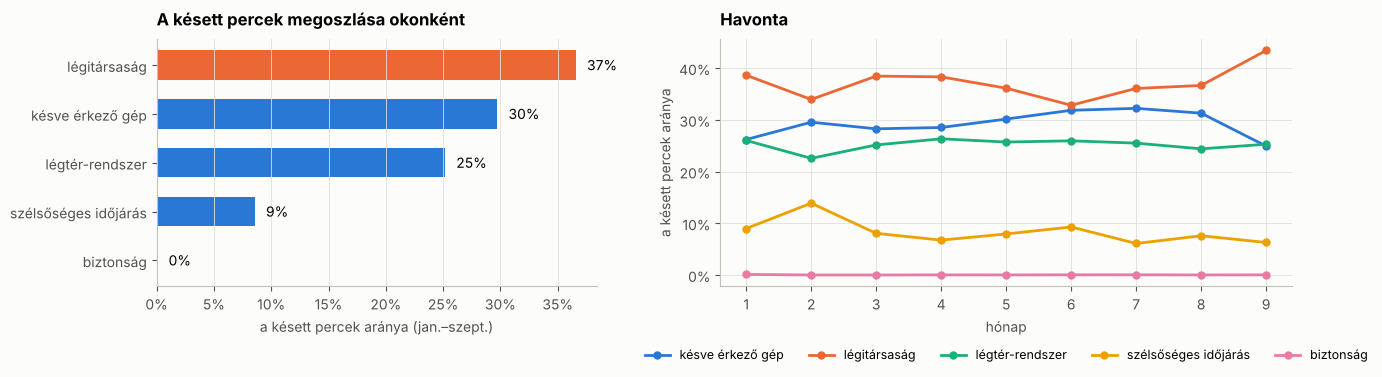

késve érkező gép        29.7 %
légitársaság            36.6 %
légtér-rendszer         25.1 %
szélsőséges időjárás     8.5 %
biztonság                0.0 %


In [6]:
CAUSES = {"LATE_AIRCRAFT_DELAY": "késve érkező gép", "AIRLINE_DELAY": "légitársaság", "AIR_SYSTEM_DELAY": "légtér-rendszer",
          "WEATHER_DELAY": "szélsőséges időjárás", "SECURITY_DELAY": "biztonság"}
mins = done[list(CAUSES)].rename(columns=CAUSES)
share = mins.sum() / mins.sum().sum()
monthly = mins.groupby(done.MONTH).sum()
monthly = monthly.div(monthly.sum(axis=1), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.3]})
s = share.sort_values()
ax[0].barh(s.index, s.values, color=[C["orange"] if v == s.max() else C["blue"] for v in s.values], height=0.6)
for i, v in enumerate(s.values):
    ax[0].text(v + 0.01, i, f"{v:.0%}", va="center")
ax[0].xaxis.set_major_formatter(pct); ax[0].grid(axis="y", visible=False)
ax[0].set(title="A késett percek megoszlása okonként", xlabel="a késett percek aránya (jan.–szept.)")
for col, name in zip([C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"]], CAUSES.values()):
    ax[1].plot(monthly.index, monthly[name], "o-", color=col, lw=2, ms=5, label=name)
ax[1].yaxis.set_major_formatter(pct); ax[1].set_xticks(range(1, 10))
ax[1].set(title="Havonta", xlabel="hónap", ylabel="a késett percek aránya")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9, ncol=5)
plt.tight_layout(); plt.show()
print((share * 100).round(1).astype(str).add(" %").to_string())

*Értelmezés:* a késett percek 37%-a légitársasági ok, 30%-a késve érkező gép, 25%-a légtér-rendszer, 9%-a szélsőséges időjárás. A biztonsági ok gyakorlatilag 0%. A megoszlás havonta stabil, csak februárban ugrik az időjárás 14%-ra, szeptemberben pedig a légitársasági ok 43%-ra. **Döntés:** a gép előző járata (30%) a legígéretesebb jellemző. A „szélsőséges időjárás” csak 9%, de az időjárás a légtér-rendszer okon keresztül is hat, ezért az időjárás-összekapcsolás (2. rész) megéri. A biztonsági ok elhagyható.

## 6. Mikor késnek a járatok?

**Kérdés:** nő-e a késés a nap folyamán, és melyik napokon nagyobb? **Döntés:** az indulás órája és a hét napja jellemző.

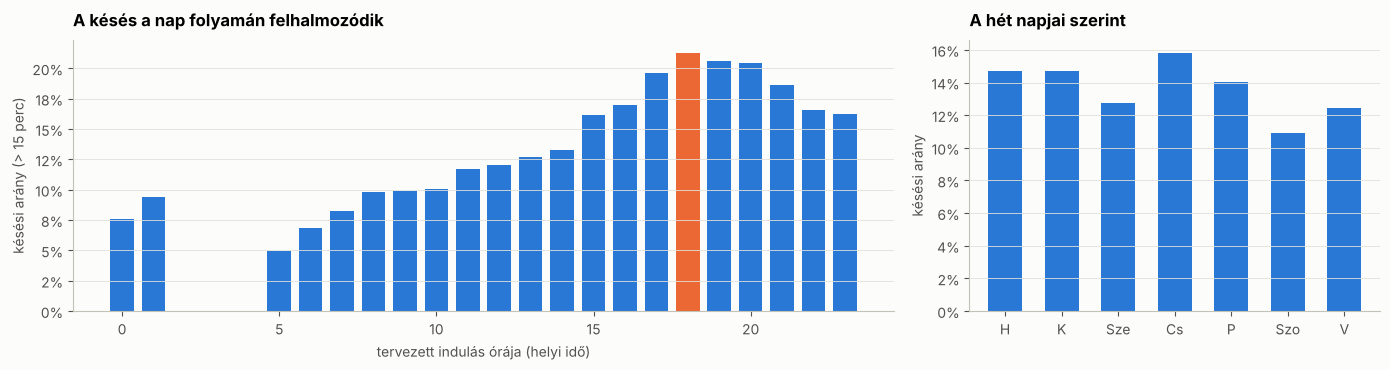

legkisebb: 5 óra (5.0%) | legnagyobb: 18 óra (21.3%)


In [7]:
by_hour = done.groupby("dep_hour").delayed.agg(["mean", "size"])
by_hour = by_hour[by_hour["size"] >= 100]
by_dow = done.groupby("DAY_OF_WEEK").delayed.mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].bar(by_hour.index, by_hour["mean"], color=C["blue"], width=0.75)
peak = by_hour["mean"].idxmax()
ax[0].bar(peak, by_hour.loc[peak, "mean"], color=C["orange"], width=0.75)
ax[0].yaxis.set_major_formatter(pct); ax[0].grid(axis="x", visible=False)
ax[0].set(title="A késés a nap folyamán felhalmozódik", xlabel="tervezett indulás órája (helyi idő)", ylabel="késési arány (> 15 perc)")
ax[1].bar(["H", "K", "Sze", "Cs", "P", "Szo", "V"], by_dow.values, color=C["blue"], width=0.6)
ax[1].yaxis.set_major_formatter(pct); ax[1].grid(axis="x", visible=False)
ax[1].set(title="A hét napjai szerint", ylabel="késési arány")
plt.tight_layout(); plt.show()
print(f"legkisebb: {by_hour['mean'].idxmin()} óra ({by_hour['mean'].min():.1%}) | legnagyobb: {peak} óra ({by_hour['mean'].max():.1%})")

*Értelmezés:* a késési arány reggel 5 órakor a legkisebb (5,0%), és a nap folyamán szinte folyamatosan nő, egészen a 18 órás csúcsig (21,3%). Este enyhén csökken (23 órakor 16,3%). A hét napjai között kisebb a különbség: a csütörtök a legrosszabb (15,8%), a szombat a legjobb (10,9%). **Döntés:** az indulás órája erős jellemző, nem lineárisan (kategóriaként vagy spline-nal). A hét napja gyengébb, de bekerül.

**Kérdés:** van-e szezonalitás, és kiugranak-e az ünnepek vagy a viharos napok? **Döntés:** az időrendi split, és egy ünnep-jellemző.

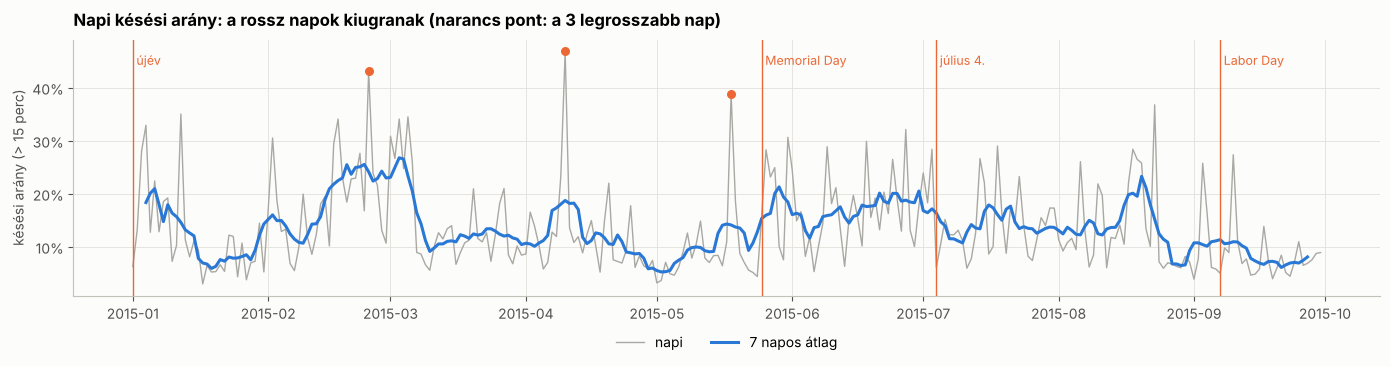

a 3 legrosszabb nap: {'2015-04-10': '47%', '2015-02-24': '43%', '2015-05-18': '39%'}
havi késési arány: {1: '12.2%', 2: '18.9%', 3: '14.6%', 4: '12.2%', 5: '12.0%', 6: '16.7%', 7: '14.8%', 8: '13.7%', 9: '8.9%'}


In [8]:
daily = done.groupby("date").delayed.mean()
HOLIDAYS = {"2015-01-01": "újév", "2015-05-25": "Memorial Day", "2015-07-04": "július 4.", "2015-09-07": "Labor Day"}
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(daily.index, daily.values, color=C["grey"], lw=1, label="napi")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=C["blue"], lw=2.2, label="7 napos átlag")
for d, name in HOLIDAYS.items():
    if pd.Timestamp(d) in daily.index:
        ax.axvline(pd.Timestamp(d), color=C["orange"], lw=1)
        ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.95, " " + name, color=C["orange"], fontsize=9, va="top")
worst = daily.nlargest(3)
ax.scatter(worst.index, worst.values, color=C["orange"], zorder=3, s=30)
ax.yaxis.set_major_formatter(pct); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set(title="Napi késési arány: a rossz napok kiugranak (narancs pont: a 3 legrosszabb nap)", ylabel="késési arány (> 15 perc)")
plt.tight_layout(); plt.show()
print("a 3 legrosszabb nap:", {d.date().isoformat(): f"{v:.0%}" for d, v in worst.items()})
print("havi késési arány:", {m: f"{v:.1%}" for m, v in done.groupby("MONTH").delayed.mean().items()})

*Értelmezés:* erős a szezonalitás: a havi késési arány februárban a legmagasabb (18,9%), júniusban 16,7%, szeptemberben a legalacsonyabb (8,9%). A legrosszabb napok egy-egy viharhoz köthetők (2015-04-10: 47%, 2015-02-24: 43%, 2015-05-18: 39%). Magukon az ünnepnapokon kifejezetten kevés a késés (jan. 1.: 6,3%, júl. 4.: 6,1%, Labor Day: 5,0%), a körülöttük lévő utazási napokon viszont sok (jan. 3–4.: 28–33%, a Memorial Day utáni nap: 28%, júl. 3.: 28%). **Döntés:** az időrendi split indokolt. A szeptember a legkönnyebb hónap, ezért a validációs foldok (júl., aug., szept.) között nagy lesz a szórás, és a nov.–dec. teszt valószínűleg nehezebb lesz. Az ünnep-jellemző maga az ünnep helyett az *ünnep közelségét* mérje (±1–2 nap), ami a téli teszten (hálaadás, karácsony) különösen számíthat. A legrosszabb napokat az időjárás magyarázhatja.

## 7. Hol késnek a járatok?

**Kérdés:** mely repülőterekről induló Delta-járatok késnek a legtöbbet? **Döntés:** reptér-jellemző; a történeti késési arány csak foldon belül (célkódolás).

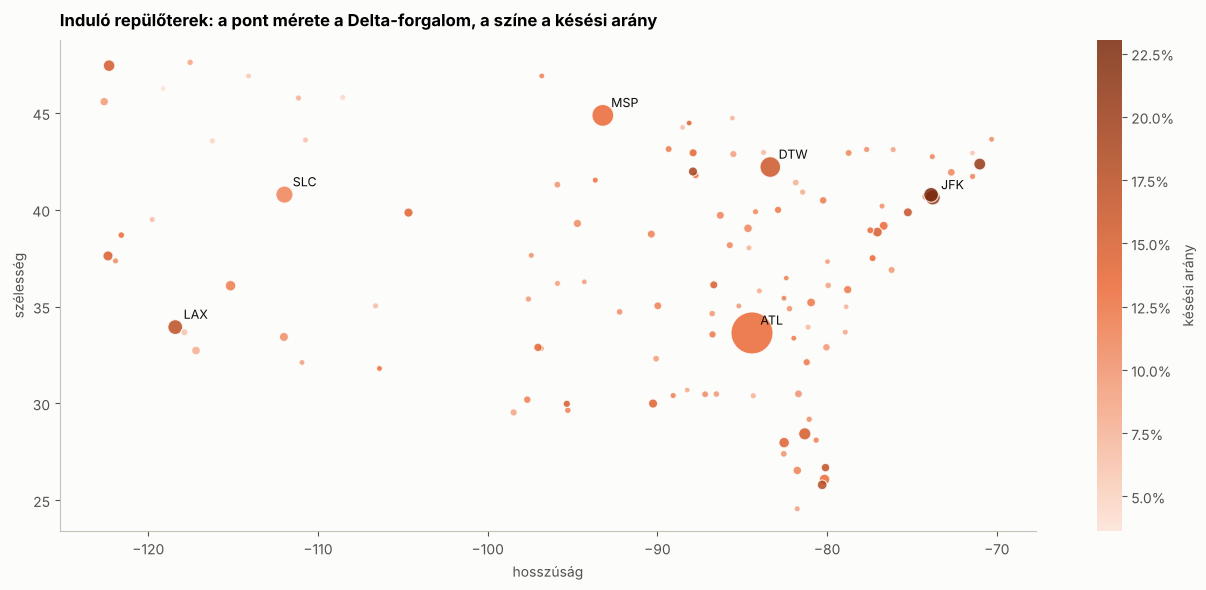

,ORIGIN_AIRPORT,CITY,járat,arány
5,ATL,Atlanta,181054,0.133
99,MSP,Minneapolis,46273,0.133
42,DTW,Detroit,41256,0.158
139,SLC,Salt Lake City,27409,0.112
75,JFK,New York,20599,0.205
80,LAX,Los Angeles,19915,0.174
83,LGA,New York,19438,0.230
87,MCO,Orlando,12533,0.154
17,BOS,Boston,11690,0.207
133,SEA,Seattle,10943,0.156


In [9]:
ap = pd.read_csv(DATA / "airports.csv")
by_ap = done.groupby("ORIGIN_AIRPORT").delayed.agg(arány="mean", járat="size").reset_index()
by_ap = by_ap.merge(ap, left_on="ORIGIN_AIRPORT", right_on="IATA_CODE")
by_ap = by_ap[(by_ap.járat >= 300) & by_ap.LONGITUDE.between(-130, -60) & by_ap.LATITUDE.between(23, 50)]   # a szárazföldi USA
fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(by_ap.LONGITUDE, by_ap.LATITUDE, s=by_ap.járat / by_ap.járat.max() * 900 + 15, c=by_ap.arány, cmap=SEQ,
                alpha=0.85, edgecolors="#fcfcfb", linewidths=0.8)
for _, r in by_ap.nlargest(6, "járat").iterrows():
    ax.annotate(r.ORIGIN_AIRPORT, (r.LONGITUDE, r.LATITUDE), textcoords="offset points", xytext=(6, 6), fontsize=9, color=C["ink"])
cb = plt.colorbar(sc, ax=ax, format=PercentFormatter(1.0, decimals=1)); cb.set_label("késési arány"); cb.outline.set_visible(False)
ax.set(title="Induló repülőterek: a pont mérete a Delta-forgalom, a színe a késési arány", xlabel="hosszúság", ylabel="szélesség"); ax.grid(False)
plt.tight_layout(); plt.show()
by_ap.sort_values("járat", ascending=False)[["ORIGIN_AIRPORT", "CITY", "járat", "arány"]].head(10)

*Értelmezés:* az atlantai központból (ATL) indul a tanító járatok közel 28%-a (181 054), ennek késési aránya (13,3%) éppen átlagos. A legrosszabbak a zsúfolt északkeleti repülőterek: LaGuardia 23,0%, Boston 20,7%, JFK 20,5%. Salt Lake City a legjobb a nagyok közül (11,2%). **Döntés:** az induló repülőtér bekerül jellemzőnek. A kis forgalmú repülőterek miatt a történeti késési arányt foldon belül, simított célkódolással számoljuk.

## 8. Zsúfoltság

**Kérdés:** nagyobb-e a késés, ha az adott órában sok gép indul a repülőtérről (az összes légitársasággal együtt)? **Döntés:** forgalom-jellemző (a menetrendből előre ismert).

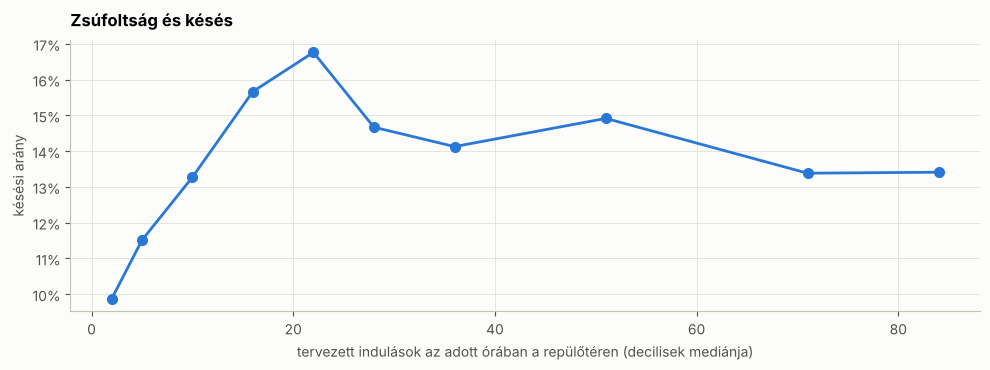

,forgalom,arány
traffic,,
"(0.999, 3.0]",2.000,0.099
"(3.0, 7.0]",5.000,0.115
"(7.0, 12.0]",10.000,0.133
"(12.0, 19.0]",16.000,0.157
"(19.0, 24.0]",22.000,0.168
"(24.0, 31.0]",28.000,0.147
"(31.0, 41.0]",36.000,0.141
"(41.0, 59.0]",51.000,0.149
"(59.0, 78.0]",71.000,0.134


In [10]:
done = done.join(traffic, on=["ORIGIN_AIRPORT", "MONTH", "DAY", "dep_hour"])
bins = pd.qcut(done.traffic, 10, duplicates="drop")
by_traf = done.groupby(bins, observed=True).agg(forgalom=("traffic", "median"), arány=("delayed", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(by_traf.forgalom, by_traf.arány, "o-", color=C["blue"], lw=2, ms=7)
ax.yaxis.set_major_formatter(pct)
ax.set(title="Zsúfoltság és késés", xlabel="tervezett indulások az adott órában a repülőtéren (decilisek mediánja)", ylabel="késési arány")
plt.tight_layout(); plt.show()
by_traf

*Értelmezés:* az összefüggés **nem monoton**. A késési arány a legkisebb forgalomtól (≤3 indulás/óra: 9,9%) a közepes forgalomig nő (19–24 indulás/óra: 16,8%), afölött viszont visszaesik 13–15%-ra. A legnagyobb forgalmú órák főleg az ATL csúcsai, és az atlantai központ átlagos késési arányú. A forgalom itt tehát részben a repülőteret méri. **Döntés:** a forgalom-jellemző bekerül, de csak a repülőtér mellett, fákkal (RF/XGBoost) érdemes nem lineárisan kezelni. Önálló hatását a modellben ellenőrizzük.

## 9. Továbbgyűrűzik-e a késés?

**Kérdés:** ha a gép előző járata késett, a következő is késik? És számít-e a fordulóidő (az előző járat tervezett érkezése és ennek tervezett indulása között)?
**Döntés:** a projekt legerősebb jellemzője. *(Itt leíró elemzés: az előző járat tényleges késését nézzük. A modellben csak az lesz jellemző, ami az indulás előtt 2 órával már ismert.)*

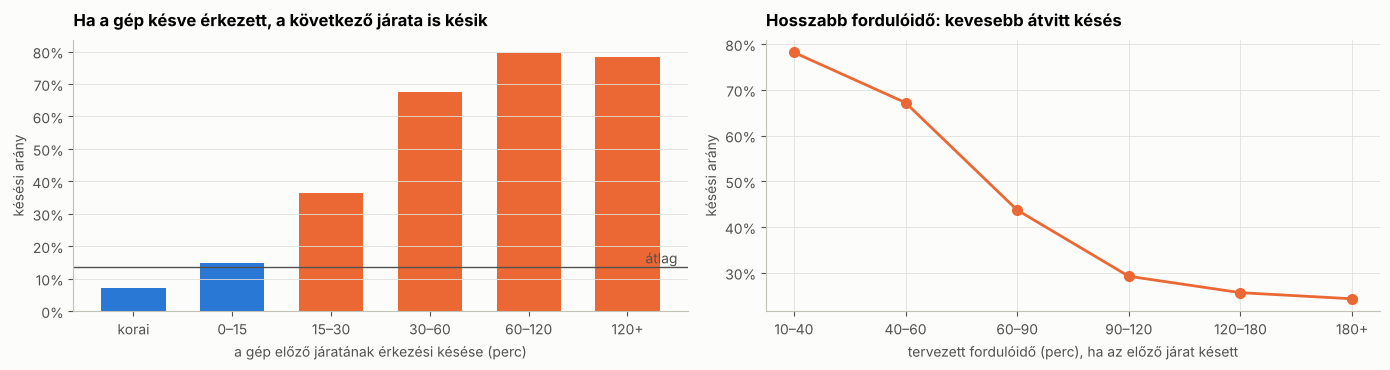

korreláció (az előző járat és a mostani érkezési késése, ugyanazon a napon): 0.48 | a gép napi első járata nélkül: 474,814 sor


,mean,size
prev_arr_delay,,
korai,0.072,343854
0–15,0.148,75718
15–30,0.363,23729
30–60,0.674,16439
60–120,0.796,9936
120+,0.783,5138


In [11]:
seq = tr[tr.TAIL_NUMBER.notna()].sort_values(["TAIL_NUMBER", "sched_dep"]).copy()
g = seq.groupby(["TAIL_NUMBER", "date"])
seq["prev_arr_delay"] = g.ARRIVAL_DELAY.shift(1)
arr_hhmm = g.SCHEDULED_ARRIVAL.shift(1)
prev_arr = seq.date + pd.to_timedelta(arr_hhmm // 100, unit="h") + pd.to_timedelta(arr_hhmm % 100, unit="m")
seq["turn_min"] = (seq.sched_dep - prev_arr).dt.total_seconds() / 60          # tervezett fordulóidő (perc)
seq = seq[seq.prev_arr_delay.notna() & seq.delayed.notna() & seq.turn_min.between(10, 600)]

prev_bins = pd.cut(seq.prev_arr_delay, [-np.inf, 0, 15, 30, 60, 120, np.inf], labels=["korai", "0–15", "15–30", "30–60", "60–120", "120+"])
by_prev = seq.groupby(prev_bins, observed=True).delayed.agg(["mean", "size"])
late_prev = seq[seq.prev_arr_delay > 15]
turn_bins = pd.cut(late_prev.turn_min, [10, 40, 60, 90, 120, 180, 600], labels=["10–40", "40–60", "60–90", "90–120", "120–180", "180+"])
by_turn = late_prev.groupby(turn_bins, observed=True).delayed.agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(by_prev.index.astype(str), by_prev["mean"], width=0.65,
          color=[C["blue"] if lab in ("korai", "0–15") else C["orange"] for lab in by_prev.index.astype(str)])
ax[0].axhline(rate, color=C["ink2"], lw=1)
ax[0].text(0.99, rate, "átlag ", transform=ax[0].get_yaxis_transform(), ha="right", va="bottom", color=C["ink2"])
ax[0].yaxis.set_major_formatter(pct); ax[0].grid(axis="x", visible=False)
ax[0].set(title="Ha a gép késve érkezett, a következő járata is késik", xlabel="a gép előző járatának érkezési késése (perc)", ylabel="késési arány")
ax[1].plot(by_turn.index.astype(str), by_turn["mean"], "o-", color=C["orange"], lw=2, ms=7)
ax[1].yaxis.set_major_formatter(pct)
ax[1].set(title="Hosszabb fordulóidő: kevesebb átvitt késés", xlabel="tervezett fordulóidő (perc), ha az előző járat késett", ylabel="késési arány")
plt.tight_layout(); plt.show()
print(f"korreláció (az előző járat és a mostani érkezési késése, ugyanazon a napon): {seq.prev_arr_delay.corr(seq.ARRIVAL_DELAY):.2f} | "
      f"a gép napi első járata nélkül: {len(seq):,} sor")
by_prev

*Értelmezés:* a projekt legerősebb jele. Ha a gép előző járata korábban érkezett, a következő járat csak 7,2%-ban késik. 15–30 perces előző késésnél az arány 36,3%, 60 perc fölött ~78–80%. Az előző és a mostani érkezési késés korrelációja 0,48. A fordulóidő tompít: késett előző járat után 10–40 perces fordulóval 78% késik, 90 perc fölött már csak 24–29%. **Döntés:** a gép előző járata és a tervezett fordulóidő a fő jellemzők. Az indulás előtt 2 órával azonban csak az az előző járat használható, amely addigra már megérkezett (vagy annak indulási késése). Ezt a 3. részben gondosan kell felépíteni, különben szivárgás lesz.

## 10. Törlések és elterelések

**Kérdés:** milyen gyakori, és miért? **Döntés:** a fő elemzésből kimaradnak (nincs érkezési késésük), de a korlátoknál említjük.
Ok-kódok: A = légitársaság, B = időjárás, C = légtér-rendszer, D = biztonság.

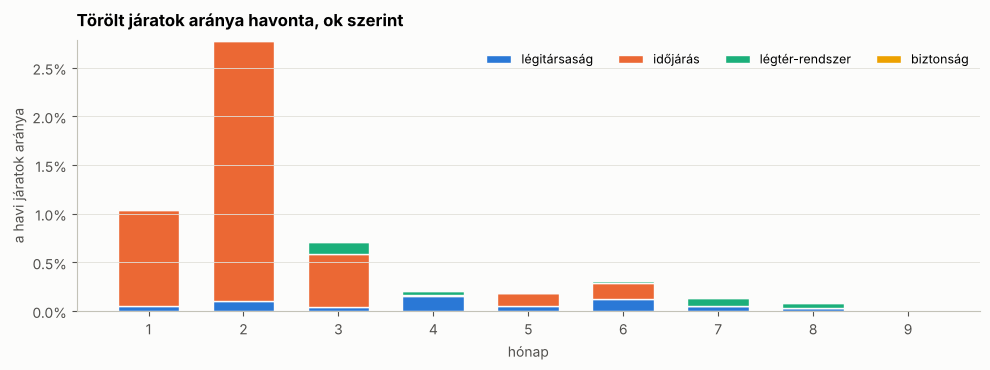

törölt: 0.55% | elterelt: 0.22% (a tanító időszakon)


In [12]:
canc = tr[tr.CANCELLED == 1]
by_reason = canc.groupby(["MONTH", "CANCELLATION_REASON"]).size().unstack(fill_value=0)
by_reason = by_reason.reindex(columns=["A", "B", "C", "D"], fill_value=0).div(tr.groupby("MONTH").size(), axis=0)
fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(by_reason))
for code, name, col in [("A", "légitársaság", C["blue"]), ("B", "időjárás", C["orange"]), ("C", "légtér-rendszer", C["aqua"]), ("D", "biztonság", C["yellow"])]:
    ax.bar(by_reason.index, by_reason[code], bottom=bottom, color=col, label=name, width=0.65, edgecolor="#fcfcfb", linewidth=1)
    bottom += by_reason[code].values
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1)); ax.set_xticks(range(1, 10)); ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=4, fontsize=9)
ax.set(title="Törölt járatok aránya havonta, ok szerint", xlabel="hónap", ylabel="a havi járatok aránya")
plt.tight_layout(); plt.show()
print(f"törölt: {tr.CANCELLED.mean():.2%} | elterelt: {tr.DIVERTED.mean():.2%} (a tanító időszakon)")

*Értelmezés:* a tanító időszakban a Delta-járatok 0,55%-át törölték és 0,22%-át terelték el, ez együtt ~0,8%. A törlések 81%-a időjárás miatt történt (B), főleg januárban és februárban (2,79%). Nyár végére a törlési arány 0,1% alá esik. **Döntés:** a törölt és elterelt járatok kimaradnak a célból. Ez enyhén torzít: éppen a legrosszabb időjárású napok legrosszabb járatai hiányoznak, ezt a korlátoknál megemlítjük.

## 11. Összefoglaló: amit az EDA alapján a modellezésben csinálunk

**Az adat:** 875 881 Delta-járat (az összes 2015-ös járat 15,1%-a), ebből a tanító időszakban (jan.–szept.) 657 462, ebből 652 391 érkezett meg. A 15 percnél nagyobb érkezési késés aránya **13,7%**, ezért a fő mutató a PR-AUC (véletlen szint ~0,14), az alapráta-modell 13,7%-ot jósol mindenkinek. Az adat tiszta: nincs „2400”, a lajstromjel csak 26 sorból hiányzik. Az októberi Delta-járatok mind számkódú repülőtérrel szerepelnek, ezért az október kimarad. A törölt és elterelt járatokat (~0,8%) kizárjuk.

**Jellemzők a 3. részhez, várható erősségük szerint:** (1) a gép előző járatának késése és a tervezett fordulóidő: 7%-ról akár 80% fölé emeli a késési arányt, de csak az indulás előtt 2 órával már ismert információ használható; (2) az indulás órája (5,0% → 21,3%); (3) a hónap és a napi időjárás-viszonyok; (4) az induló és az érkező repülőtér, célkódolással foldon belül; (5) a hét napja és az óránkénti forgalom (ez utóbbi nem monoton). Az ünnep közelsége (±1–2 nap) is bekerül: magukon az ünnepnapokon kevés a késés, de a körülöttük lévő utazási napokon sok.

**A 2. részhez (időjárás):** az időjárás a késett percek 9%-át adja közvetlenül, de a légtér-rendszer okon (25%) keresztül is hat, és a legrosszabb napok (2015-04-10, 02-24, 05-18) is időjárási napoknak tűnnek. Ezért érdemes összekapcsolni. **Kockázat:** a szeptember feltűnően könnyű (8,9%), így a validációs foldok között nagy lesz a szórás, és a téli ünnepi teszt (nov.–dec.) nehezebb lehet, mint a validáció.